<!--

    Gaia Data Processing and Analysis Consortium (DPAC) 
    Co-ordination Unit 9 Work Package 930
    
    (c) 2005-2025 Gaia DPAC
    
    This program is free software: you can redistribute it and/or modify
    it under the terms of the GNU General Public License as published by
    the Free Software Foundation, either version 3 of the License, or
    (at your option) any later version.

    This program is distributed in the hope that it will be useful,
    but WITHOUT ANY WARRANTY; without even the implied warranty of
    MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
    GNU General Public License for more details.

    You should have received a copy of the GNU General Public License
    along with this program.  If not, see <https://www.gnu.org/licenses/>.
    -->

This note book shows a simple example of statistical aggregations over the entire sky catalogue. Visualisation employs the HEALPixel pixelisation encoded in the Gaia source identifier.

In [1]:
# Import the spark config
from astroflow_spark_gaia import spark

# set the required HEALPixelisation level here:
healpix_level = 6
# HEALPix level : no. of pixels
# 4 : 3072
# 5 : 12288
# 6 : 49152 ~ 1 square degree pixels
# 7 : 196608

In [2]:
import math

# compute relevant pixelisation quantities
nside = int(math.pow(2, healpix_level))
powers_of_2 = 35 + (12 - healpix_level)*2
divisor = int(math.pow(2, powers_of_2))

# formulate SQL query
query = "SELECT floor(source_id /  %d"%(divisor) + ") AS hpx_id, COUNT(*) AS n, AVG(pmra) AS avg_pmra, AVG(pmdec) AS avg_pmdec FROM gaia_source GROUP BY hpx_id"

# define a data frame aggregation of the relevant quantities (note this is cached for use in two subsequent cells)
df = spark.sql(query).cache()

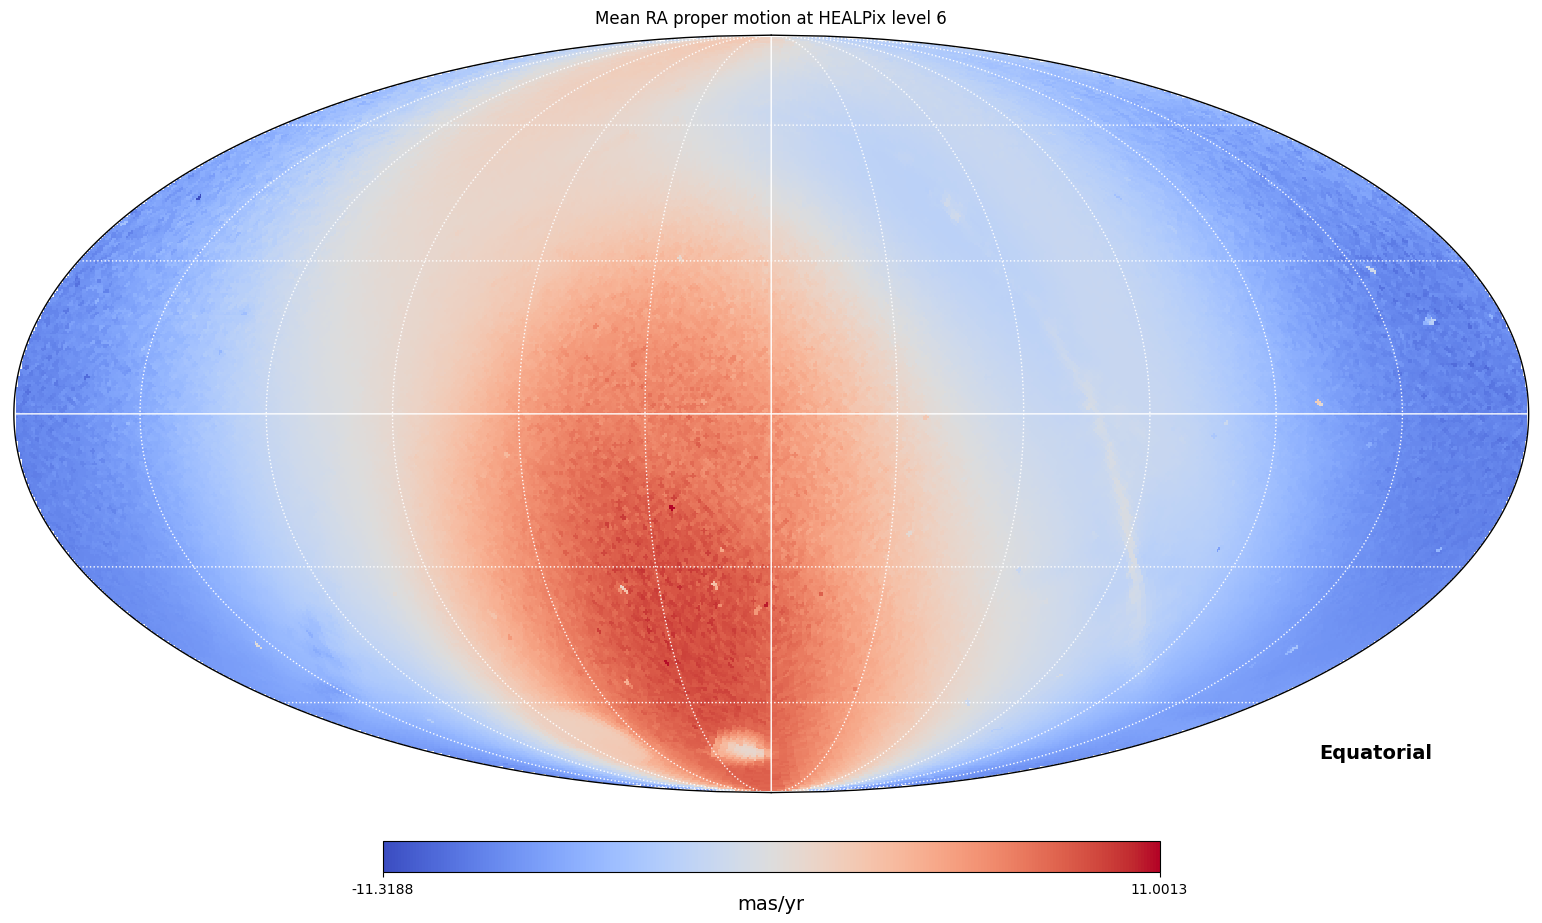

In [3]:
# plot up the sky counts
import matplotlib.pyplot as plot
import numpy as np
import healpy as hp

# set a figure to use along with a plot size (landscape, golden ratio)
plot.figure(1, figsize = (16.18, 10.0))

# healpy constants appropriate to the HEALPix indexing encoded in Gaia source IDs
npix = hp.nside2npix(nside)

# do the visualisation
array_data = np.empty(npix)
for item in df.rdd.collect():  array_data[item[0]] = item[2]
hp.mollview(array_data, fig = 1, coord='C', unit='mas/yr', nest=True, title='Mean RA proper motion at HEALPix level %d'%(healpix_level), cmap='coolwarm')
hp.graticule(coord='C', color='white')

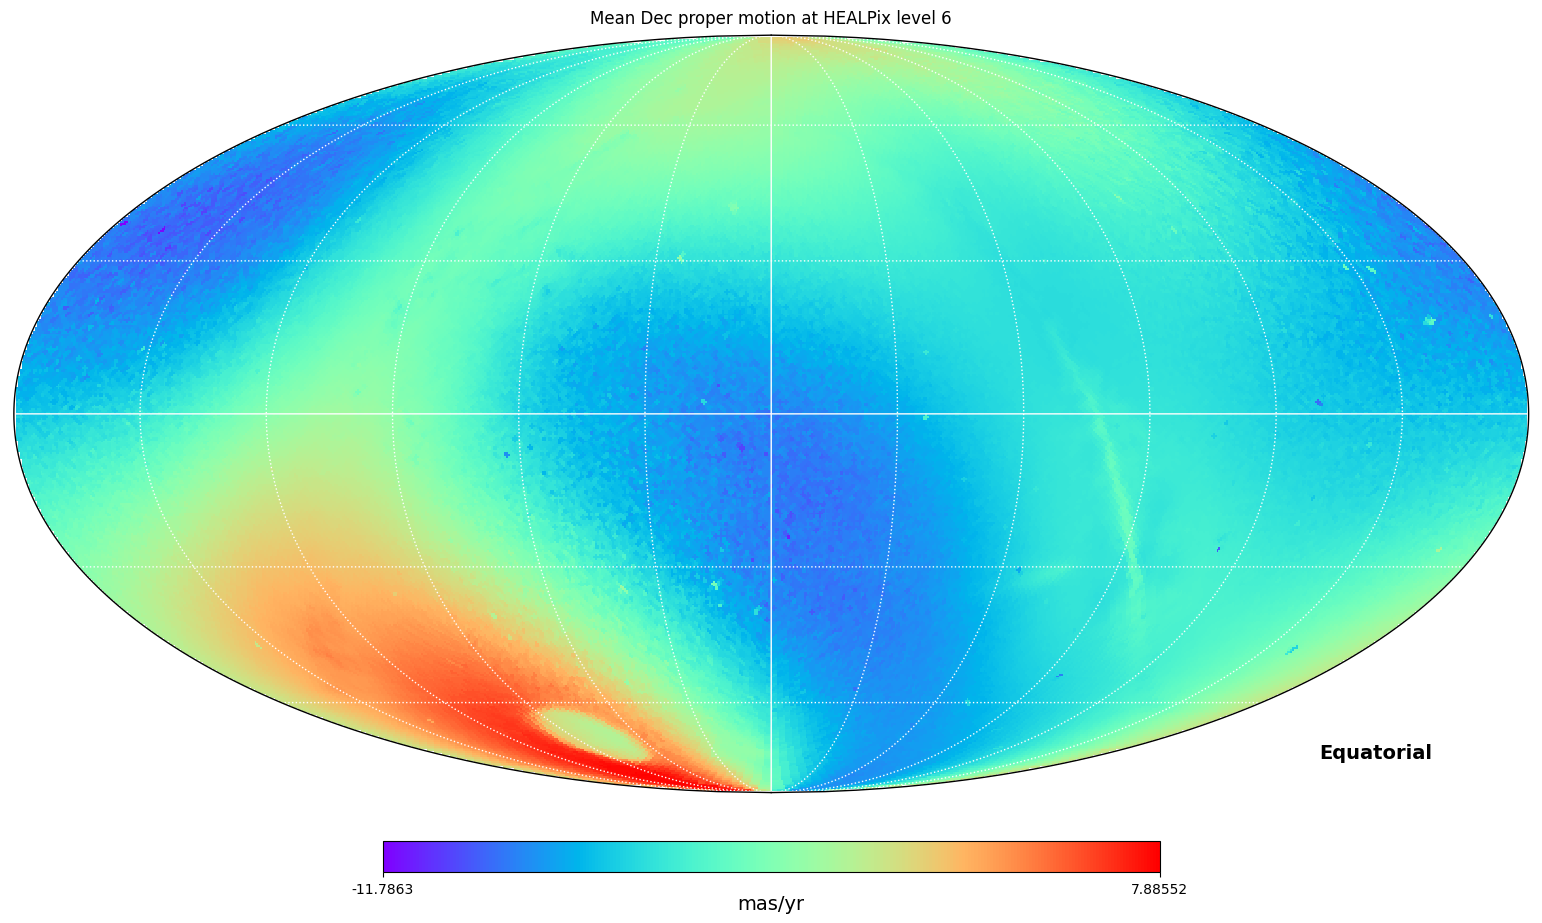

In [4]:
plot.figure(2, figsize = (16.18, 10.0))

array_data = np.empty(npix)
for item in df.rdd.collect():  array_data[item[0]] = item[3]
hp.mollview(array_data, fig=2, coord='C', unit='mas/yr', nest=True, title='Mean Dec proper motion at HEALPix level %d'%(healpix_level), cmap='rainbow')
hp.graticule(coord='C', color='white')

In [6]:
spark.catalog.clearCache()

* [Gaia source ID definition (for HEALPix indexing)](https://dms.cosmos.esa.int/COSMOS/doc_fetch.php?id=2779219)
* [Python package healpy](https://healpy.readthedocs.io/en/latest/index.html)
* [Python matplotlib plotting library](https://matplotlib.org)
* [Handy HEALPixel characteristics for various levels](https://lambda.gsfc.nasa.gov/toolbox/pixelcoords.html)

